In [1]:
import json
with open("../../outputs/hpo/fixed_hpo/outputs.json", "r") as f:
    hpo_data = json.load(f)
with open("../../hpo/baseline_metrics.json", "r") as f:
    baseline_metrics = json.load(f)
print(baseline_metrics)

{'promoter_no_tata': {'mean': 0.7420857209666549, 'std': 0.00825544239869875, 'metric': 'val/mcc'}, 'H4K20me1': {'mean': 0.546681667447458, 'std': 0.01317334487953775, 'metric': 'val/mcc'}, 'H3K4me2': {'mean': 0.473280844250837, 'std': 0.007468769533808587, 'metric': 'val/mcc'}, 'promoter_all': {'mean': 0.7169109532736063, 'std': 0.00477370143055105, 'metric': 'val/mcc'}, 'H3K4me1': {'mean': 0.4040404113460082, 'std': 0.009953884460596387, 'metric': 'val/mcc'}, 'enhancers': {'mean': 0.49312815098430535, 'std': 0.002702191337782939, 'metric': 'val/mcc'}, 'promoter_tata': {'mean': 0.7214279669067885, 'std': 0.009989613782587342, 'metric': 'val/mcc'}, 'splice_sites_acceptors': {'mean': 0.50843269451932, 'std': 0.011123823298570088, 'metric': 'val/mcc'}, 'H2AFZ': {'mean': 0.39972925202073895, 'std': 0.009192948926767518, 'metric': 'val/mcc'}, 'H3K4me3': {'mean': 0.6124106981152095, 'std': 0.0131705686625567, 'metric': 'val/mcc'}, 'H3K9ac': {'mean': 0.5034676193498381, 'std': 0.010911141644

In [2]:
trial_scores = {}
for trial in hpo_data.keys():
    trial_scores[trial] = {}

for dataset_name in ("nt_benchmark", "genomic_benchmark", "bend_benchmark", "chromatin_profile_prediction"):
    def get_tasks(trial):
        global dataset_name
        if dataset_name == "chromatin_profile_prediction":
            cpp = trial.get("chromatin_profile_prediction")
            if cpp is not None:
                return {"chromatin_profile_prediction": cpp}
            else:
                return None
        else:
            return trial.get(dataset_name)

    for trial in hpo_data.keys():
        tasks = get_tasks(hpo_data[trial])

        if tasks is not None:
            for name, val in tasks.items():
                if name == "pretraining": 
                    continue
                trial_scores[trial][name] = val[0][baseline_metrics[name]["metric"]]

In [3]:
# Cleanup
for trial_key in list(trial_scores.keys()):
    if len(trial_scores[trial_key]) != 30:
        del trial_scores[trial_key]
    else:
        trial_scores[int(trial_key)] = trial_scores[trial_key]
        del trial_scores[trial_key]

In [4]:
# Turn it into df
import pandas as pd
df = pd.DataFrame.from_dict(trial_scores, orient="index")
print(df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 21 entries, 0 to 20
Data columns (total 30 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   splice_sites_acceptors            21 non-null     float64
 1   H3K27me3                          21 non-null     float64
 2   splice_sites_all                  21 non-null     float64
 3   H3K4me2                           21 non-null     float64
 4   H2AFZ                             21 non-null     float64
 5   H3K4me1                           21 non-null     float64
 6   H3K27ac                           21 non-null     float64
 7   H3K9me3                           21 non-null     float64
 8   H3K4me3                           21 non-null     float64
 9   enhancers_types                   21 non-null     float64
 10  promoter_all                      21 non-null     float64
 11  enhancers                         21 non-null     float64
 12  promoter_tata  

In [5]:
def metrics_into_z_scores(df):
    return df.apply(lambda col: (col - baseline_metrics[col.name]["mean"]) / baseline_metrics[col.name]["std"], axis=0)

z_scores = metrics_into_z_scores(df)

In [6]:
records = (df == df.max()).sum(axis=1)
records_list = sorted(list(records), reverse=True)
print([*records_list]) # The sum of records_list is higher than 30 because when there's a tie, it gives a record to all the tied trials.

[5, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0]


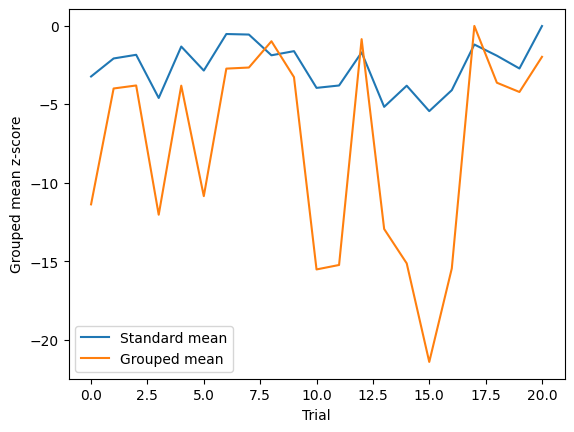

In [7]:
# Plot the grouped mean vs plain mean
from matplotlib import pyplot as plt

TASKS_GROUPS = {
    "histone": [
        "H2AFZ",
        "H3K27ac",
        "H3K27me3",
        "H3K36me3",
        "H3K4me1",
        "H3K4me2",
        "H3K4me3",
        "H3K9ac",
        "H3K9me3",
        "H4K20me1",
    ],
    "promoter": [
        "promoter_all",
        "promoter_tata",
        "promoter_no_tata",
        "human_nontata_promoters",
    ],
    "enhancers": [
        "enhancers",
        "enhancers_types",
        "dummy_mouse_enhancers_ensembl",
        "human_enhancers_cohn",
        "human_enhancers_ensembl",
        "human_ensembl_regulatory",
        "human_ocr_ensembl",
        "drosophila_enhancers_stark"
    ],
    "splicing": [
        "splice_sites_all",
        "splice_sites_donors",
        "splice_sites_acceptors",
    ],
    "general_genomic_content": [
        "demo_coding_vs_intergenomic_seqs",
        "demo_human_or_worm",
    ],
    "gene_finding": ["gene_finding"],
    "cpg_methylation": ["cpg_methylation"],
    "chromatin_profile_prediction": ["chromatin_profile_prediction"]
}

def compute_means(df):
    groups = [df[TASKS_GROUPS[group]].mean(axis=1) for group in TASKS_GROUPS]
    grouped_means = pd.concat(groups, axis=1).mean(axis=1) # The axis for pd.concat specifies the resulting series direction, I wanna concatenate the series as columns
    df["grouped_means"] = grouped_means
    df["plain_means"] = df.drop(columns=["grouped_means"]).mean(axis=1)

compute_means(z_scores)
ax = z_scores[["plain_means", "grouped_means"]].plot(xlabel="Trial", ylabel="Grouped mean z-score")
ax.legend(["Standard mean", "Grouped mean"])
plt.savefig("./grouped_z_score.png", dpi=300)
plt.show()

In [8]:
from optuna.visualization import (
    plot_optimization_history,
    plot_param_importances,
)
import optuna

study = optuna.load_study(study_name="hpo", storage="sqlite:///../../outputs/hpo/fixed_hpo/optuna.db")
opt_history = plot_optimization_history(study)
opt_history.update_layout(
    title=None,                # quita el título
    width=700,                 # ancho en px
    height=350,                # alto en px (aspect ratio 2:1)
    margin=dict(l=50, r=20, t=10, b=40),   # márgenes chicos, sin el espacio del título
    font=dict(size=12),
)
opt_history.show()

param_importances = plot_param_importances(study)
param_importances.update_layout(
    title=None,                # quita el título
    width=700,                 # ancho en px
    height=350,                # alto en px (aspect ratio 2:1)
    margin=dict(l=50, r=20, t=10, b=40),   # márgenes chicos, sin el espacio del título
    font=dict(size=12),
)
param_importances.show()

print(study.best_params)
opt_history.write_image("./opt_history.png", scale=5)
param_importances.write_image("./param_importances.png", scale=5)

{'overlapping_segments_canonicalization': 'partial_break', 'annotations_level': 2, 'include_cdjv_segments': 'false', 'include_pseudogenes': 'true', 'transformation': 'complement'}


In [9]:
# Compute the p-values for near-scored trials

# Start by computing the variance of the grouped z-score mean, 1/k + 1/k^2 * (sum of covariances without the diagonal)
# Plain mean will be used for simplicity
# import numpy as np

# cov_matrix = np.load("../../hpo/baseline_correlation_matrix.npy")
# grouped_mean_variance = (1/30) + (1 / 30 ** 2) * (np.sum(cov_matrix) - np.trace(cov_matrix))

# # Now, the t-tests
# from scipy import stats
# def t_test(good_trial, bad_trial):
#     plain_means = list(z_scores["plain_means"])
#     t_value = (plain_means[good_trial] - plain_means[bad_trial]) / (np.sqrt(grouped_mean_variance * (1 + 1/5))) # sigma²=grouped_mean_variance, n_a=1 and n_b=5
#     p = stats.t.sf(t_value, df=4)
#     print(f"{good_trial} - {bad_trial} has a p-value of {p}")
#     return p

# t_test(20, 10)

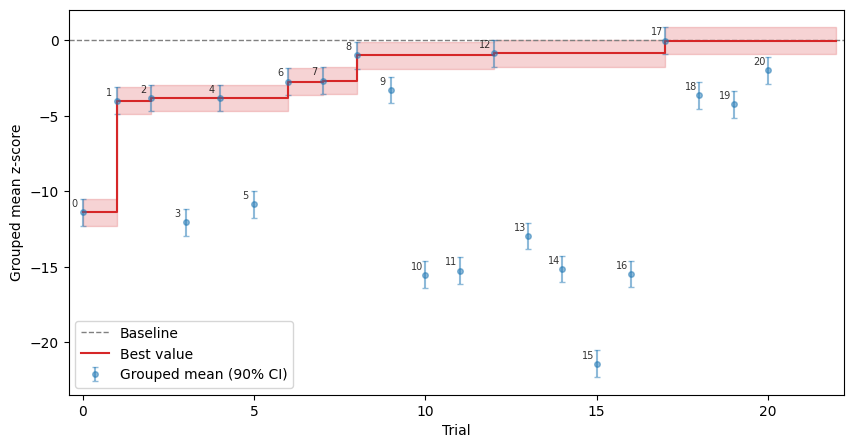

In [16]:
import numpy as np
import pandas as pd
from scipy import stats
from matplotlib import pyplot as plt

with open("../../hpo/baseline_results.json", "r") as f:
    baseline_results = json.load(f)

baseline_results = pd.DataFrame(baseline_results)
baseline_z = metrics_into_z_scores(baseline_results)

def grouped_mean(df):
    """Media de las medias por grupo (solo columnas de tareas)."""
    return pd.concat(
        [df[cols].mean(axis=1) for cols in TASKS_GROUPS.values()], axis=1
    ).mean(axis=1)

# --- Ruido del baseline ---
# baseline_z: (n repeticiones x tareas), mismas columnas que z_scores
n = len(baseline_z)
sigma_S = grouped_mean(baseline_z).std(ddof=1)
tcrit = stats.t.ppf(0.95, df=n - 1)

# --- Score por trial ---
score = grouped_mean(z_scores)
S = score.to_numpy()
T = len(S)
x = np.arange(T)

# Repeticiones por trial (1 si no repetiste). Si repetiste alguno, pasá una Series con su r.
reps = pd.Series(1, index=z_scores.index)
r = reps.reindex(score.index).fillna(1).to_numpy()
se = sigma_S / np.sqrt(r)

# --- Best so far y su incertidumbre ---
idx_best = np.zeros(T, dtype=int)
cur = 0
for i in range(T):
    if S[i] > S[cur]:
        cur = i
    idx_best[i] = cur
best_so_far = S[idx_best]
se_best = se[idx_best]

# --- Extensión a la derecha del último trial ---
ext_frac = 0.08                                # cuánto se extiende, como fracción de T
ext = max(1, int(np.ceil(ext_frac * T)))
x_ext = np.append(x, x[-1] + ext)
best_ext = np.append(best_so_far, best_so_far[-1])
se_best_ext = np.append(se_best, se_best[-1])

# --- Gráfico ---
fig, ax = plt.subplots(figsize=(10, 5))

# Ruido de una corrida del baseline
ax.axhline(0, color="gray", ls="--", lw=1, label="Baseline")

# Trials con su intervalo
ax.errorbar(x, S, yerr=tcrit * se, fmt="o", ms=4, capsize=2,
            alpha=0.5, color="tab:blue", label="Grouped mean (90% CI)")

# Números de trial encima de cada punto
trial_nums = score.index  # o z_scores.index, lo que tenga el número real de trial
for xi, yi, ti in zip(x, S, trial_nums):
    ax.annotate(str(ti), (xi, yi),
                textcoords="offset points", xytext=(-6, 4),
                ha="center", fontsize=7, color="black", alpha=0.8)

# Best so far con su banda, extendida más allá del último trial
ax.step(x_ext, best_ext, where="post", color="tab:red", label="Best value")
ax.fill_between(x_ext, best_ext - tcrit * se_best_ext, best_ext + tcrit * se_best_ext,
                step="post", color="tab:red", alpha=0.2)

ax.set_xlim(x[0] - 0.02 * T, x_ext[-1] + 0.01 * T)
ax.set_xlabel("Trial")
ax.set_ylabel("Grouped mean z-score")
ax.legend()
plt.savefig("./grouped_z_score_history.png", dpi=300)
plt.show()

In [ ]:
# Check the generalist model vs each specialist model. This should be done with the repeated trials to get p-values
generalist = df.iloc[z_scores["grouped_means"].idxmax()]
specialists = df.max()
print(list(specialists))
print(list(generalist))

diffs = specialists - generalist
diffs.plot.bar()

NameError: name 'df' is not defined